## Overview of plasmid loss model 

#### Data Provided
- Survival curve of both antibiotics over time (in CFU with respect to time)
- Growth curves of transformed bacteria (in $OD_{600}$)
- Final proportion of plasmid-containing colonies to plasmid-free colonies upon plating


#### Assumptions made
- Sister cells of bacteria which no longer contain their plasmid (F) still have the same survival probability as parent
- Plasmid loss rate is a constant and does not vary according to other factors like time since inoculation or relative population density
- PFB do not replicate under antibiotic exposure
- The $OD_{600}$ curve provided can be directly used to find doubling time
- Plasmid-containing bacteria (C) do not die over the course of the experiment
- Plasmid loss happens at division
- When bacteria lose their plasmid, their survival probability as a function of time is identical to non-transformed bacteria with time of exposure beginning at loss time. 




#### ODE form: 
Where $\beta$ is the growth rate, $C_0, F_0$ are the initial proportions of C and F, L is the plasmid loss rate with respect to time, $t$ is the variable time, $T$ is the length of the survival curve(determined by maximum bacteria survival time for a treatment), and p(t) is the probability of a plasmid-free surviving at $T - t$ hours away from plating. 

The change in C with respect to time is proportionate to its growth minus its loss, both of which are proportionate to C itself, which motivates the differential equation:$\\$
$$\frac{dC}{dt} = C*\beta - C * L = C(\beta - L)  = C*(\beta - L)$$

Solving for C given the DE above gives the following: $\\$
$$C(t) = C_0 * e^{\left((\beta - L) * t \right)}$$

Which also gives us $\beta$ looking at just the growth portion of the equation. Since division is doubling, and we have the doubling time $d$ from the data:$\\$
$$
\begin{aligned}
P &= e^{\beta * t}\\
2 &= e^{\beta * d}\\
\frac{\ln 2}{d} &= \beta
\end{aligned}
$$

The change in the plasmid free proportion of bacteria is proportionate to the loss rate, probability of survival at time of loss, and the solution for C which we derived above. $\\$
$$\frac{dF}{dt} = C(t) * L * p(t) = e^{\left((\beta - L) * t \right)} * L * p(t)$$

Integration and substitution of $C(t)$ gives the following expression, which does not have a closed form due to the nature of $p(t)$. $T$ is defined as the amount of time it takes for exposure to an antibiotic treatment to reduce the survival rate of a cell without the resistance plasmid to some precision approaching 0: $\\$
$$F = L * \int_{0}^{T}e^{\left((\beta - L) * t \right)} * p(t)dt $$

And since the final piece of data gives us the proportion of $R = \frac{C}{F}$, and since only the proportion of $\frac{C}{F}$ matter, we can set the initials $C_0 = 1, F_0 = 0$ as C represents 100% of the population at t = 0 which appears at plating. As a result they do not appear in the final equation: $\\$ 
$$R = \frac{e^{(\beta - L) * T}}{L * \int_{0}^{T}e^{(\beta - L) * t} * p(t)dt}$$

And as L cannot be isolated in the expression above, it has to be computed numerically. Since $L$ is initially computed with respect to time, and loss per division, $L_{div}$ is more biologically interpretable, we multiply $L$ by the doubling time. $$L_{div} = L * d$$ 




/var/folders/h5/1pq34wc10wn_4xghv5656y840000gn/T/ipykernel_1083/1952620038.py:84: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  grouped = df.groupby(df.columns, axis=1).mean()
/var/folders/h5/1pq34wc10wn_4xghv5656y840000gn/T/ipykernel_1083/1952620038.py:84: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  grouped = df.groupby(df.columns, axis=1).mean()
/var/folders/h5/1pq34wc10wn_4xghv5656y840000gn/T/ipykernel_1083/1952620038.py:52: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_new[col] = pd.to_numeric(df_new[col], errors='coerce')
/var/folders/h5/1pq34wc10wn_4xghv5656y840000gn/T/ipykernel_1083/1952620038.py:67: FutureWa

Plasmid Loss Rates (per division):
Kanamycin: 0.0002 ± 0.0001
Carbenicillin: 0.0002 ± 0.0001


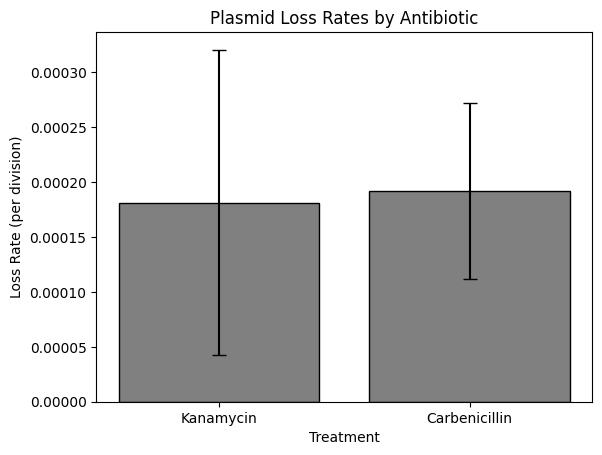

In [8]:
#!/usr/bin/env python3
# Viraj Arora

import math
import matplotlib.pyplot as plt # type: ignore
import numpy as np # type: ignore
import pandas as pd # type: ignore
import scipy as sp # type: ignore

class findPlasmidLossRate:


    def __init__(self, od_pcb, viability, prop_dark):

        self.od_pcb = od_pcb
        self.viability = viability
        self.prop_dark = prop_dark

        #loads dataframes from the three input files
        self.odpcb_df   = pd.read_csv(self.od_pcb, sep='\t') 
        self.death_df   = pd.read_csv(self.viability, sep='\t')
        self.propdark_df = pd.read_csv(self.prop_dark, index_col=0) # prop_dark file is a csv where all relevant data is in rows labelled "delta 6 #A$"
        #

        # gets the average of the replicates for each treatment in each dataframe and stores it as a new dataframe
        self.avg_odpcb_df = self.averageReplicates(self.odpcb_df)
        self.avg_via_df = self.averageReplicates(self.death_df)

        self.proportions_df = self.cleanPropDark(self.propdark_df) # uses helper method to pull necessary data from prop_dark file, and averages over replicates

        #calculates the doubling time to be used for all calculations of plasmid loss rate 
        self.d_time = self.getDoublingTime()
    
    def cleanPropDark(self, df: pd.DataFrame) -> pd.DataFrame:
        '''
        Takes the experimental data of rows labeled with 'delta #X' and returns a dataframe with final plasmid loss proportions for each antibiotic treatment. Colony counts are averaged over each replicate, denoted by shared number. 
        '''

        df_new = df[df.index.str.contains(r'delta\s\d', regex=True, na=False)]

        count = sum(df_new.index.str.contains(r'delta\s\d', regex=True))

        length_new = int(count / 5)

        cleaned_data = pd.DataFrame({'Carbenicillin': [0] * length_new, 'Kanamycin' : [0] * length_new}, 
                                    index=[f'row{i}' for i in range(length_new)]
                        )

        # converts to numeric values(1) -> sum plating counts over each replicate and calculate overall proportion (2) ->  get average proportions for replicates of each treatment(3)

        for col in df_new.columns: #(1)
            df_new[col] = pd.to_numeric(df_new[col], errors='coerce') 

        # this step is done with respect to the exact dimensions of the data given, so needs to be modified if data format changes
        for ind in range(len(df_new)): #(3)
            if ind % 5 == 4: # 5 works due to it being th enumber of trials per replicate
                count = int(ind / 5)
                temp_row = df_new.iloc[ind - 4:ind + 1].sum() #(2)

                prev_val = None

                # implementation specific to format given, just gets dark colonies and total colonies for each treatment
                for ind, val in enumerate(temp_row.values):
                    if ind % 2 == 0:
                        prev_val = val
                    elif ind % 2 == 1:
                        cleaned_data.iloc[int(count), (ind-1) // 2] = prev_val / val

                cleaned_data = cleaned_data.rename(index={cleaned_data.index[count]: 'delta' + str(count + 1) + '(avg)'})
                
        return cleaned_data
        
        

    def averageReplicates(self, df: pd.DataFrame) -> pd.DataFrame:
        '''
        Averages replicate columns in a dataframe by shared treatment tag.
        '''
        # turns empty cells become NaN (avoids errors in averaging)
        df = df.replace(r'^\s*$', np.nan, regex=True)
        df.columns = df.columns.str.replace(r'\.\d+$', '', regex=True)

        # Group and average replicate columns and average them
        grouped = df.groupby(df.columns, axis=1).mean()
        return grouped

    def getDoublingTime(self):
        '''Gets the average doubling time of the population from OD data - uses the "Top10 / pGFPck Δ6" strain grown under carbenicillin as the reference culture'''
        df = self.avg_odpcb_df.copy()
        col = "Top10 / pGFPck Δ6"

        time_col = df.columns[0]

        # Calculates doubling time from the maximum and minimum OD values from the growth data and the time between them, as growth is monotonic. 
        # note : this can be changed at a later point in prefereence of a more logical interval selection rule
        max_time = df[time_col].max()
        od_fchange = df[col].max() / df[col].min()
        dtime = max_time / (math.log(od_fchange) / math.log(2))

        return dtime
    
    def getLosses(self):
        '''Get plasmid loss rates for each replicate and treatment'''
        loss_rates = {'Kanamycin': [], 'Carbenicillin': []} # empty dictionary to store loss rates

        for ind, row in self.proportions_df.iterrows():
            if ind != 'total_avg':
                rates_curr = self.getLoss(row)
                for key in rates_curr:
                    if key.split('.')[0] == 'Carbenicillin':
                        loss_rates['Carbenicillin'].append(rates_curr[key])
                    elif key.split('.')[0] == 'Kanamycin':
                        loss_rates['Kanamycin'].append(rates_curr[key])

        
        return loss_rates

    def getLoss(self, row: pd.Series) -> dict: 
        'compute the loss rate for one replicate of each treatment'

        beta = math.log(2) / self.d_time
        rates = {}
        for treatment in row.index:
            #strips .x from treatment labels in propdark_df to match them with the labels in the viability dataframe
            treat = treatment.split('.')[0]
            prop_dark = row[treatment]
            # calculates C / F, assumes data is in form of percentage of dark cells
            prop = float(prop_dark)
            R = (1 - prop) / prop

            # gets a linear interpolation of the survival curve for current treatment label 
            time_col = self.avg_via_df['Hours']
            via_prop = self.avg_via_df[treat]
            valid_prop = via_prop.notna()
            valid_time = time_col[valid_prop]
            valid_prop = via_prop[valid_prop]

            T = valid_time.max() # gets the length of the survival curve
            p = lambda t: np.interp(t, valid_time, valid_prop) # defines the survival function as a linear interpolation of the viability data for the current treatment

            # calculates the loss rate using the formula derived in the notebook, wiht scipy's quad and brentq (root finder) functions
            # note: the step subtracts by the final plasmid loss ratio observed at plating to turn the numerical method into a root finding problem (i.e. solve for L such that the equation equals 0)
            rates[treatment] = sp.optimize.brentq(lambda L: 
                np.exp((beta-L)*T) / (L * sp.integrate.quad(lambda t: np.exp((beta-L)*t) * p(T-t), 0, T)[0]) - R, 
                1e-10, 10)
            rates[treatment] = rates[treatment] * self.d_time # converts loss rate to per division by multiplying by doubling time

        return rates
    

    



def main():
    ''''''
    odpcb_file = "OD_values_growth_curve_uv_vs_ck_070126.txt" # fixed file to load growth rate data for plasmid-containing bacteria
    viability_file = "NORMALIZED_CFU_vs_time.txt" # fixed file to load viability data for plasmid-free bacteria in order to estimate survival rates of bacteria who lose their plasmid

    prop_dark_file = "new_data.csv" # does not necessarily have to be fixed for this script. Can adjust to import single percentage numbers instead replicate data. 

    plasmid_loss_obj = findPlasmidLossRate(odpcb_file, viability_file, prop_dark_file)

    rates = plasmid_loss_obj.getLosses()  
    # handles data for each treatment to get the averages and standard deviation accordingly
    for head in rates:
        rates[head] = [np.mean(rates[head]), np.std(rates[head], ddof = 0)]
    


    print("Plasmid Loss Rates (per division):")
    for head in rates:
        print(f"{head}: {rates[head][0]:.4f} ± {rates[head][1]:.4f}")



    plt.bar(rates.keys(), [v[0] for v in rates.values()], yerr=[v[1] for v in rates.values()], capsize=5, color='gray', edgecolor='black')
    plt.ylabel("Loss Rate (per division)")
    plt.xlabel("Treatment")
    plt.title("Plasmid Loss Rates by Antibiotic")
    plt.show()


if __name__ == "__main__":
    main()